In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df=pd.read_csv(r"D:\perf_train.csv")
df1=pd.read_csv(r"D:\perf_test.csv")

In [7]:
print(df.duplicated().sum())
print(df1.duplicated().sum())

0
0


In [11]:
print(df1.shape)
print(df1.isna().sum())

(500, 21)
Employee_ID              0
Age                     33
Gender                  21
City                    46
Education_Level         49
Department              49
Experience_Years        70
Monthly_Salary          24
Projects_Completed      82
Training_Hours          68
Certifications          82
Work_Life_Balance       38
Job_Satisfaction        38
Manager_Rating          36
Overtime_Hours          53
Commute_Time_Min        57
Laptop_Issue_Count      16
Cafeteria_Rating        75
Internet_Stability      96
Last_Promotion_Years    32
Absenteeism_Days        80
dtype: int64


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           2000 non-null   int64  
 1   Age                   1873 non-null   float64
 2   Gender                1934 non-null   str    
 3   City                  1789 non-null   str    
 4   Education_Level       1806 non-null   str    
 5   Department            1801 non-null   str    
 6   Experience_Years      1747 non-null   float64
 7   Monthly_Salary        1895 non-null   float64
 8   Projects_Completed    1712 non-null   float64
 9   Training_Hours        1702 non-null   float64
 10  Certifications        1695 non-null   float64
 11  Work_Life_Balance     1819 non-null   float64
 12  Job_Satisfaction      1804 non-null   float64
 13  Manager_Rating        1853 non-null   float64
 14  Overtime_Hours        1810 non-null   float64
 15  Commute_Time_Min      1805 non-n

In [16]:
num_cols=df.select_dtypes(include=np.number).columns.drop("Employee_ID",errors="ignore")

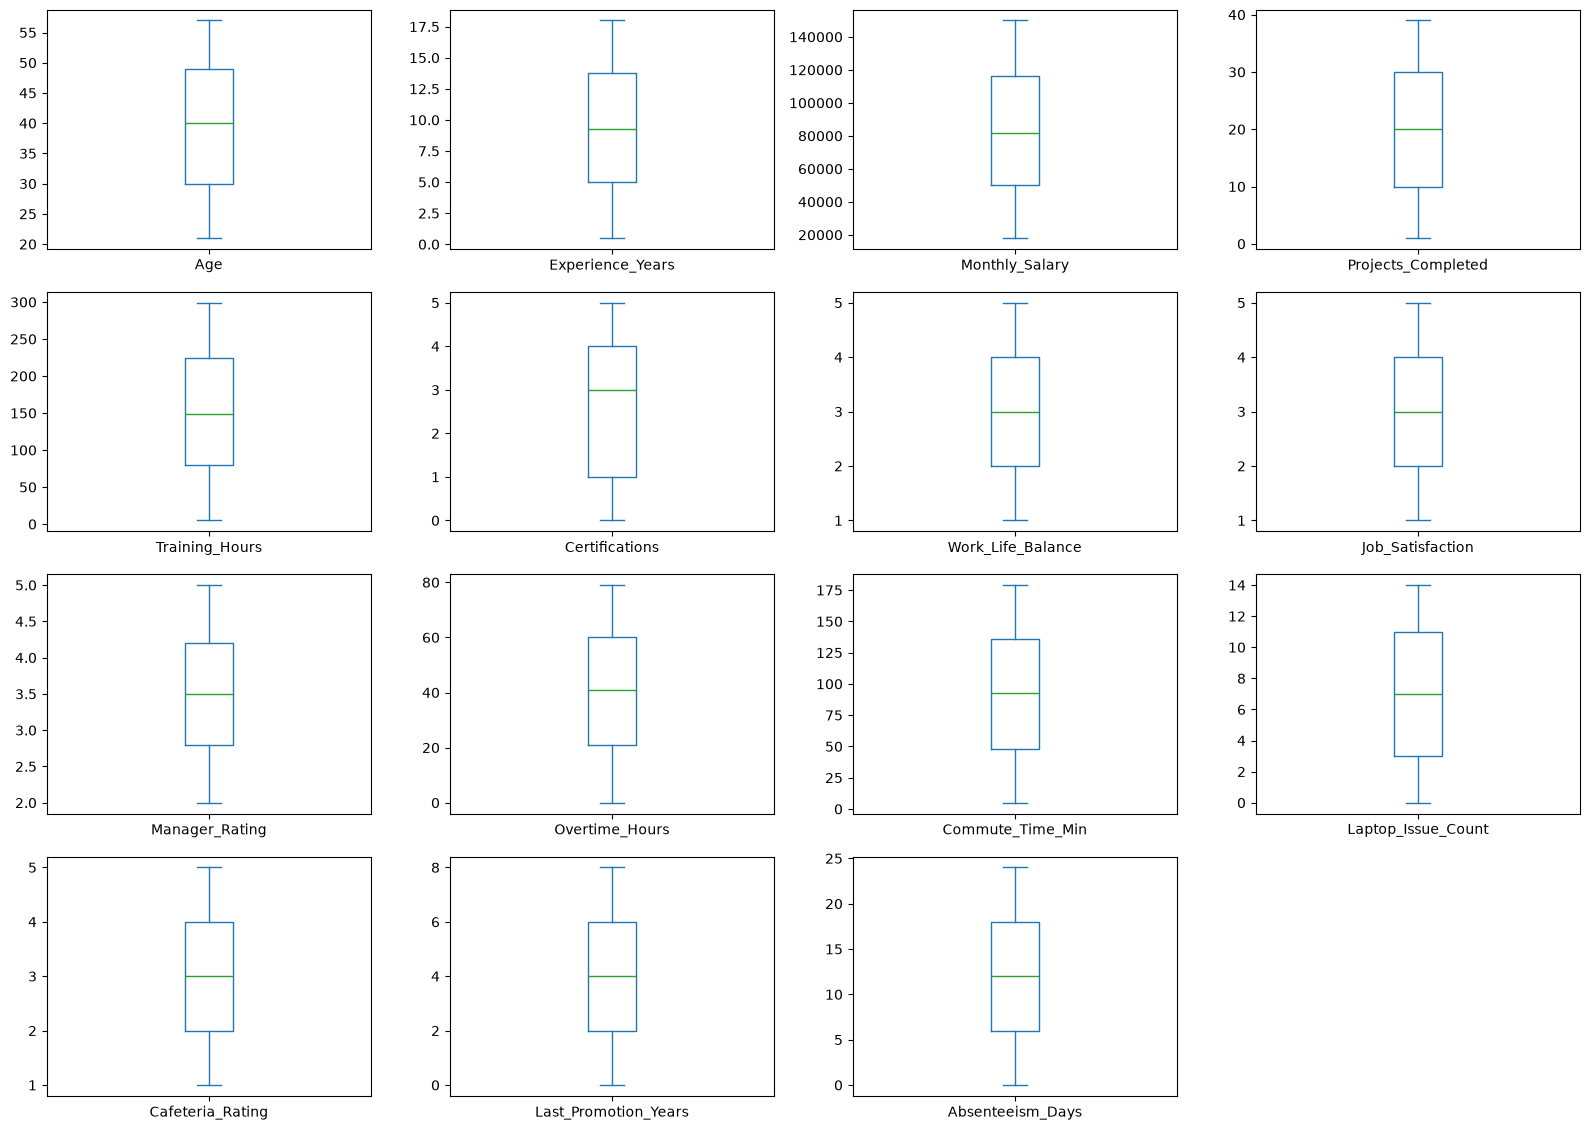

In [19]:
df[num_cols].plot(
    kind="box",
    subplots=True,
    layout=(5, 4),
    figsize=(16, 14),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [20]:
print(df[num_cols].skew().sort_values())

Work_Life_Balance      -0.056913
Overtime_Hours         -0.045959
Age                    -0.043034
Experience_Years       -0.025675
Certifications         -0.019044
Commute_Time_Min       -0.000529
Job_Satisfaction        0.007281
Manager_Rating          0.007937
Projects_Completed      0.009609
Laptop_Issue_Count      0.012751
Last_Promotion_Years    0.014108
Absenteeism_Days        0.014767
Monthly_Salary          0.026187
Training_Hours          0.043387
Cafeteria_Rating        0.072883
dtype: float64


In [32]:
for i in num_cols:
    i_men=df[i].mean()
    df[i]=df[i].fillna(i_men)
    df1[i]=df1[i].fillna(i_men)

In [35]:
cat_cols=df.select_dtypes(include=['object','str']).columns.tolist()

In [39]:
cat_cols = [
    col for col in cat_cols
    if col not in ["Performance_Category", "Employee_ID"]
]
for i in cat_cols:
    i_col = df[i].mode()[0]
    df[i] = df[i].fillna(i_col)
    df1[i] = df1[i].fillna(i_col)

In [40]:
y = df["Performance_Category"]

X = df.drop(
    columns=["Performance_Category", "Employee_ID"]
)

X_test = df1.drop(columns=["Employee_ID"])

In [41]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

In [46]:
model.fit(X_train, y_train)

y_pred = model.predict(X_valid)

print("Accuracy:", accuracy_score(y_valid, y_pred))
print(classification_report(y_valid, y_pred))

Accuracy: 0.8825
                   precision    recall  f1-score   support

Average Performer       0.88      0.96      0.92       226
   High Performer       0.69      0.66      0.68        41
    Low Performer       0.96      0.82      0.88       133

         accuracy                           0.88       400
        macro avg       0.84      0.81      0.83       400
     weighted avg       0.89      0.88      0.88       400



In [47]:
model.fit(X, y)

test_pred = model.predict(X_test)

submission = pd.DataFrame({
    "Employee_ID": df1["Employee_ID"],
    "Performance_Category": test_pred
})

submission.to_csv("employee_submission.csv", index=False)